# AutoGreen: Indian Automobile Data Analysis
**Jay Ramdatti · Data analysis mini project**

Goal: explore four-wheeler registrations, regional differences and monthly trends. This is descriptive analysis, not an ML prediction system. All results come from the supplied snapshot.

## 1. Setup and reproducible pipeline
Run from the project folder or its notebooks subfolder. The script validates the input, preserves unknown counts and recreates derived tables and charts.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'analysis.py').exists(): ROOT = ROOT.parent
assert (ROOT / 'analysis.py').exists(), 'Open this notebook inside the extracted project'
sys.path.insert(0, str(ROOT))
from analysis import load_data, build_tables, run
import pandas as pd
import matplotlib.pyplot as plt
df, tables, summary = run()

{
  "rows": 756,
  "states": 36,
  "missing": 5,
  "completeness_percent": 99.33862433862434,
  "matched_pairs": 321,
  "matched_growth_percent": 23.47014746182552,
  "matched_2025": 3227615,
  "matched_2026": 3985141,
  "total_2025": 4646012,
  "total_2026": 3985145
}


## 2. Inspect the source
One row represents a state/UT, year, month and Four Wheeler category. No manufacturer or buyer identity is present. The source download date is metadata from the uploaded file, not independent verification.

In [2]:
print(df.head(8).to_string(index=False))
print('\nColumn types:\n', df.dtypes)
print('\nYear coverage:\n', df.groupby('year').month.agg(['min','max','count']))

                state_ut  year  month vehicle_category  registrations data_status    year_coverage source_download_date                                     source_url                                                                                                  scope_note       date
Andaman & Nicobar Island  2025      1     Four Wheeler            211    reported January-December           2026-10-16 https://www.tamilnadudata.org/vehicles/states/ Four Wheeler category; not verified as Motor Car only. Registrations are not unique buyers or dealer sales. 2025-01-01
Andaman & Nicobar Island  2025      2     Four Wheeler            160    reported January-December           2026-10-16 https://www.tamilnadudata.org/vehicles/states/ Four Wheeler category; not verified as Motor Car only. Registrations are not unique buyers or dealer sales. 2025-02-01
Andaman & Nicobar Island  2025      3     Four Wheeler            144    reported January-December           2026-10-16 https://www.tamilnadud

## 3. Data quality
Keep the five missing counts as missing. Do not impute zero or invent October–December 2026 data. Duplicate keys and invalid numeric counts cause the pipeline to stop.

In [3]:
print(df[df.registrations.isna()][['state_ut','year','month','data_status']].to_string(index=False))
print('Duplicate state-month keys:', df.duplicated(['state_ut','year','month']).sum())
print('Completeness:', round(df.registrations.notna().mean()*100,2), '%')

   state_ut  year  month           data_status
Lakshadweep  2025      5 not_present_in_source
Lakshadweep  2025      9 not_present_in_source
Lakshadweep  2025     10 not_present_in_source
Lakshadweep  2025     11 not_present_in_source
Lakshadweep  2026      7 not_present_in_source
Duplicate state-month keys: 0
Completeness: 99.34 %


## 4. Fair growth comparison
A full-year 2025 total cannot be directly compared with nine months of 2026. Join state-month pairs and retain only counts reported in both years. Growth = (current total − previous total) / previous total × 100. The common-pair totals differ slightly from all reported Jan–Sep totals because missing pairs are excluded.

In [4]:
pairs = tables['pairs']
prior, current = int(pairs.prior.sum()), int(pairs.current.sum())
print('Comparable state-month pairs:', len(pairs))
print('2025 matched:', format(prior, ','))
print('2026 matched:', format(current, ','))
print('Matched growth:', round((current/prior-1)*100,2), '%')
print('\nAll reported January–September totals:\n',tables['common'].to_string())

Comparable state-month pairs: 321
2025 matched: 3,227,615
2026 matched: 3,985,141
Matched growth: 23.47 %

All reported January–September totals:
 year
2025    3227617
2026    3985145


## 5. Monthly trend
The 2026 line ends in September. Missing later months are not zero registrations. Small missing-state contributions mean national totals can be incomplete.

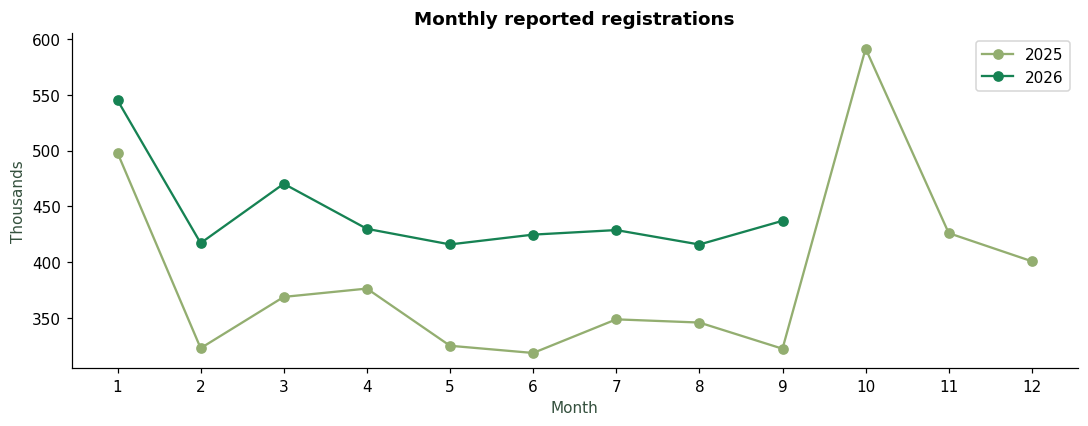

In [5]:
fig, ax = plt.subplots(figsize=(10,4))
for year, color in [(2025,'#93ae70'),(2026,'#168253')]:
    ax.plot(tables['monthly'].index,tables['monthly'][year].astype(float)/1000,marker='o',color=color,label=str(year))
ax.set(title='Monthly reported registrations',xlabel='Month',ylabel='Thousands',xticks=range(1,13))
ax.legend()
fig.tight_layout()

## 6. State comparison
Rank states by 2026 volume, then inspect matched growth separately. A high percentage on a small base is not evidence of a large market.

state_ut
Maharashtra       479614
Uttar Pradesh     421709
Gujarat           321242
Tamil Nadu        300435
Karnataka         298233
Haryana           261145
Kerala            223753
Rajasthan         213218
Madhya Pradesh    179870
Delhi             169440

Matched comparison for Gujarat and Maharashtra:
               prior  current  matched_months  growth_percent
state_ut                                                    
Gujarat      262652   321242               9           22.31
Maharashtra  394186   479614               9           21.67


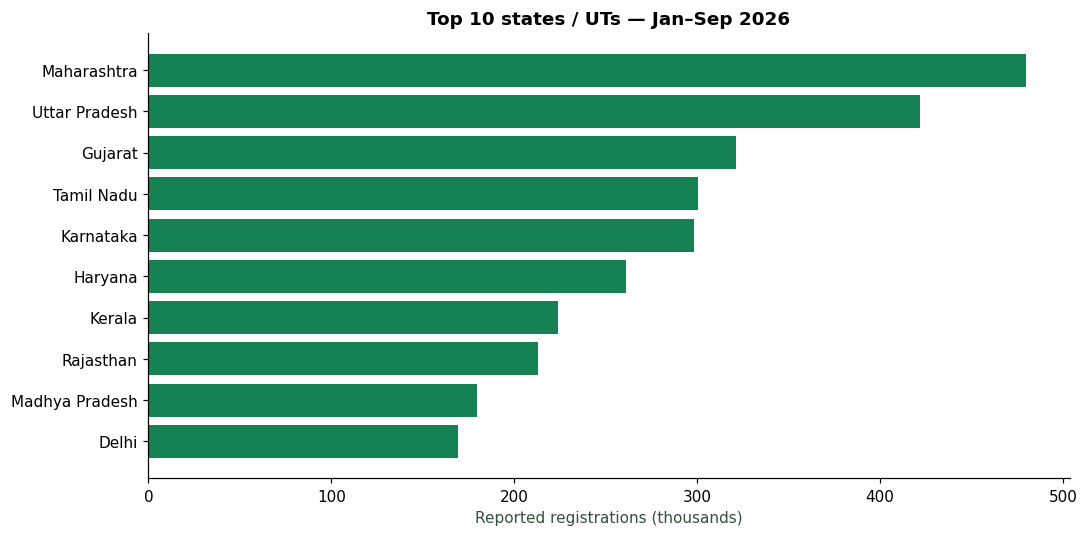

In [6]:
print(tables['states'][2026].nlargest(10).to_string())
print('\nMatched comparison for Gujarat and Maharashtra:\n', tables['growth'].loc[['Gujarat','Maharashtra']].round(2).to_string())
top = tables['states'][2026].nlargest(10).sort_values()
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(top.index,top.astype(float)/1000,color='#168253')
ax.set(title='Top 10 states / UTs — Jan–Sep 2026',xlabel='Reported registrations (thousands)')
fig.tight_layout()

## 7. Monthly pattern heatmap
Each state is normalized by its own maximum. Darker colour identifies that state’s busiest months; it must not be used to compare absolute volumes across states. Beige cells represent missing values.

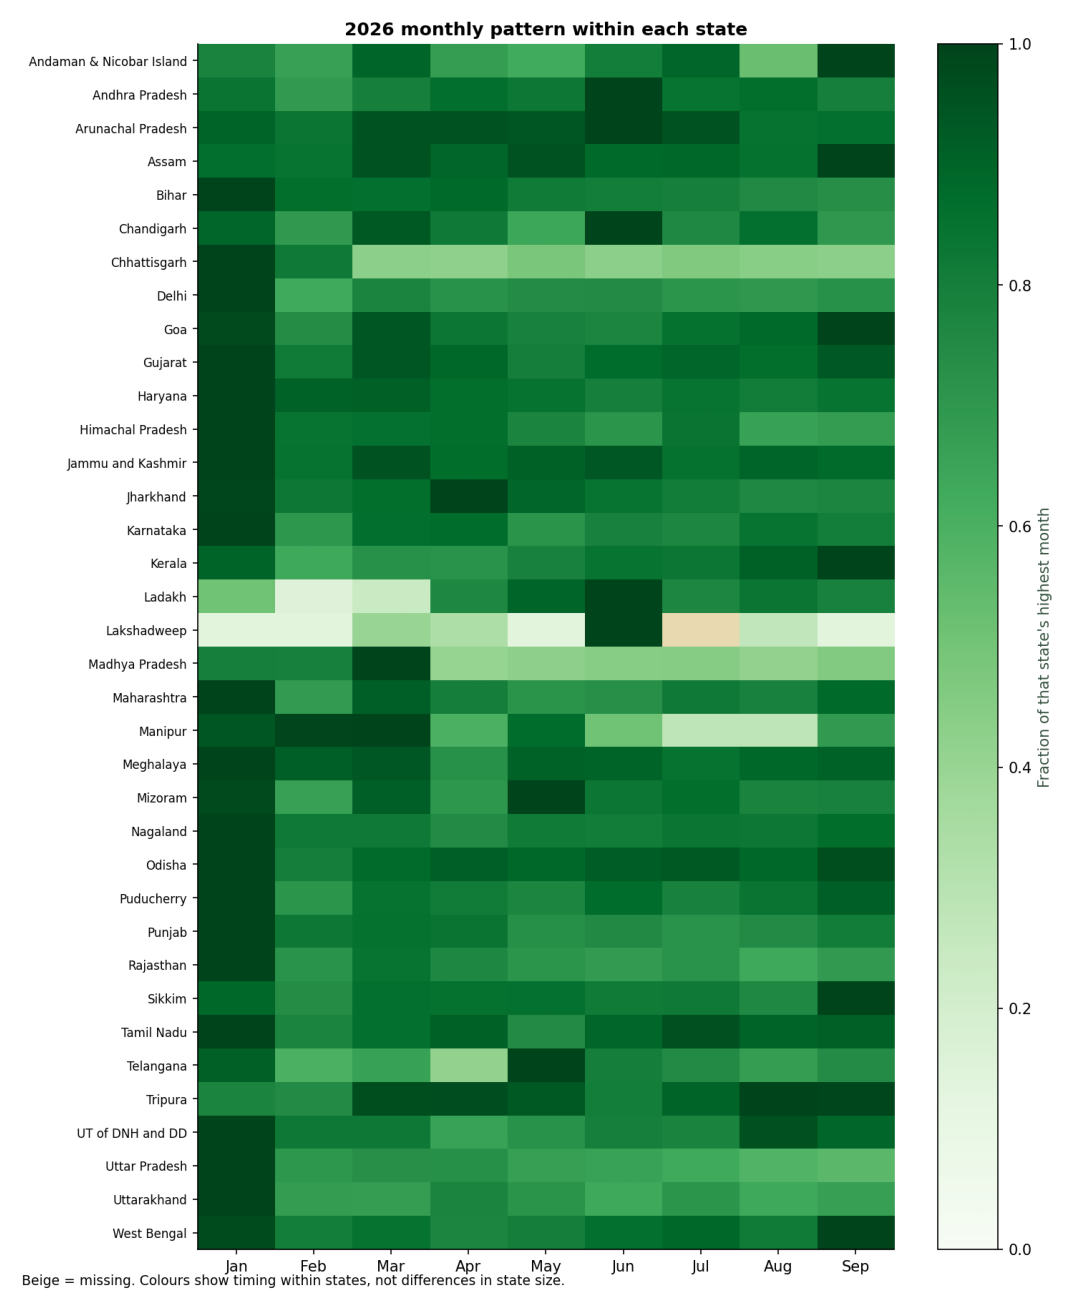

In [7]:
from matplotlib import image as mpimg
fig, ax = plt.subplots(figsize=(10,12))
ax.imshow(mpimg.imread(ROOT / 'outputs/04_heatmap.png'))
ax.axis('off')
fig.tight_layout()

## 8. Verification
Run the independent snapshot regression checks. They check source coverage, missing-value preservation, total reconciliation, matched comparison, future months and sparse-state matching.

In [8]:
import unittest
from test_analysis import AnalysisTests
result = unittest.TextTestRunner(stream=sys.stdout,verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(AnalysisTests))
assert result.wasSuccessful()

test_matched_comparison (test_analysis.AnalysisTests.test_matched_comparison) ... ok
test_missing_future (test_analysis.AnalysisTests.test_missing_future) ... ok
test_missing_not_zero (test_analysis.AnalysisTests.test_missing_not_zero) ... ok
test_small_state_pairs (test_analysis.AnalysisTests.test_small_state_pairs) ... ok
test_source_coverage (test_analysis.AnalysisTests.test_source_coverage) ... ok
test_totals_reconcile (test_analysis.AnalysisTests.test_totals_reconcile) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.021s

OK


## 9. Conclusions and limitations
- Maharashtra has the largest reported total in January–September 2026: 479,614.
- Matched registrations increased by approximately 23.47%, using 321 comparable state-month pairs.
- Five counts are missing, all for Lakshadweep.
- Registration counts do not reveal unique buyers, company sales or reasons for changes.
- The dataset covers 2025 and part of 2026 only; no five-year or company analysis is claimed.

## 10. Next steps
Acquire consistent monthly state/manufacturer data for five years, document category and company-name mappings, and extend the dashboard. Forecasting requires enough history, a chronological holdout and a tested baseline. No forecast is produced here.